# DIMSIM distance distribution: full syllable-pair population

## Main findings

1. The distribution is broad and structured: median **38.92**, interquartile range **21.52–57.92**, and 99th percentile **99.12**. This is a fixed complete population; confidence intervals and p-values are not used here.
2. Only the tone differs for **1,014** pairs (0.2%); their distances are near **0.000952**, several orders of magnitude below segmental differences. Tone matches are compared with the empirical, unbalanced tone composition rather than an assumed 20% baseline.
3. The **≥120** tail is small: **141** pairs (0.03%). Its concentration on specific syllables and distant DIMSIM coordinates (for example, `m` and `u`) suggests a strong effect of the library's coordinate scale rather than a directly calibrated acoustic distance.
4. Three broad modes near **23–24**, **40–41** and **59–60** persist across KDE bandwidths of **0.5/1/2 × Scott**; smaller peaks change with smoothing. Giving equal weight to **64,919** unique segment pairs changes the median from **38.92** to **37.76**. Tone multiplicity changes the weights but does not explain the full distribution.
5. Silhouette increases from **0.528** at `k=2` to **0.649** at the upper tested boundary, `k=10`. This is not an interior optimum and does not establish ten natural phonological clusters.
6. Gold components and the internal parser differ for **42,480** pairs. The `j/q/x + u` forms are examined separately; representation differences do not automatically imply errors in the gold labels.
7. Historical `contextual` and `character_pinyin` samples contain **12,000** pairs and cover a similar range, but use a different observational unit. They do not replace the equally weighted complete syllable-pair population.


In [1]:
from pathlib import Path
import json, sys, types
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

NOTEBOOK = Path.cwd().resolve()
PROJECT = next(path for path in [NOTEBOOK, *NOTEBOOK.parents] if (path / 'src' / 'phonetics').exists())
WORKSPACE = PROJECT.parent
SOURCE = PROJECT / 'src' / 'phonetics'
phonetics = types.ModuleType('phonetics'); phonetics.__path__ = [str(SOURCE)]
evaluation = types.ModuleType('phonetics.evaluation'); evaluation.__path__ = [str(SOURCE / 'evaluation')]
sys.modules.setdefault('phonetics', phonetics); sys.modules.setdefault('phonetics.evaluation', evaluation)
from phonetics.evaluation.distribution import load_cache, verify_bundle

CACHE = PROJECT / 'datasets' / 'evaluation-runs' / 'dimsim-distribution-20261021'
BUNDLE = PROJECT / 'datasets' / 'evaluations' / '1.0.0'
columns, summary, historical = load_cache(CACHE, code_path=SOURCE / 'evaluation' / 'distribution.py', bundle_manifest=BUNDLE / 'manifest.json')
verify_bundle(BUNDLE)  # verifies every bundle payload hash, even when the numeric cache is reused
d = columns['distance'].astype(float)
sns.set_theme(style='whitegrid', context='notebook')
print(f"Verified: {summary['validation']['syllable_count']} syllables, {summary['validation']['pair_count']:,} pairs; manifest {summary['validation']['manifest_sha256'][:12]}…")


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\ilya-\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


Verified: 967 syllables, 467,061 pairs; manifest 0a0a6b1ac02d…


## Input and formula validation

In [2]:
v = summary['validation']
pd.DataFrame({
    'check': ['complete n(n−1)/2', 'finite and non-negative', 'max bundle error', 'max formula error', 'max asymmetry', 'max diagonal'],
    'result': [v['pair_count'] == v['expected_pair_count'], v['finite'] and v['nonnegative'], v['max_bundle_absolute_error'], v['max_formula_absolute_error'], v['max_reverse_absolute_error'], v['max_diagonal_absolute_error']]
})


,check,result
0,complete n(n−1)/2,True
1,finite and non-negative,True
2,max bundle error,0.0
3,max formula error,0.0
4,max asymmetry,0.0
5,max diagonal,0.0


## Distribution

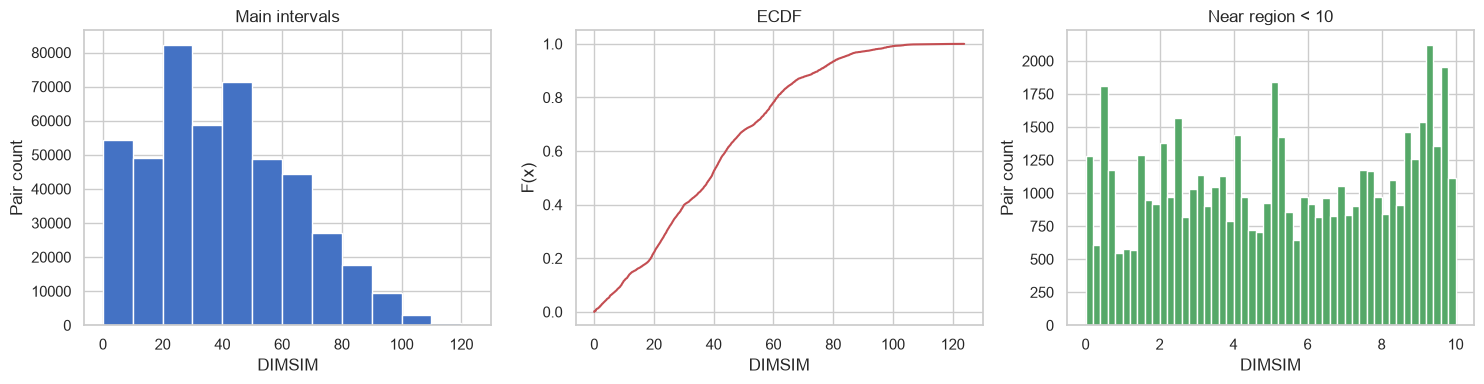

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(d, bins=np.r_[np.arange(0, 121, 10), d.max()+1e-6], color='#4472C4', edgecolor='white')
axes[0].set(title='Main intervals', xlabel='DIMSIM', ylabel='Pair count')
x = np.sort(d); axes[1].plot(x, np.arange(1, len(x)+1)/len(x), color='#C44E52')
axes[1].set(title='ECDF', xlabel='DIMSIM', ylabel='F(x)')
axes[2].hist(d[d < 10], bins=50, color='#55A868', edgecolor='white')
axes[2].set(title='Near region < 10', xlabel='DIMSIM', ylabel='Pair count')
plt.tight_layout(); plt.show()


In [4]:
bin_order = [f'[{x},{x+10})' for x in range(0, 120, 10)] + ['[120,+inf)']
pd.DataFrame(summary['bins']).T.reindex(bin_order)[['count','share','unique_syllables','equal_initial_share','equal_final_share','equal_tone_share']]


,count,share,unique_syllables,equal_initial_share,equal_final_share,equal_tone_share
"[0,10)",54296,0.11625,967,0.207382,0.215338,0.250902
"[10,20)",49108,0.105143,967,0.142828,0.110552,0.24833
"[20,30)",82358,0.176332,967,0.04121,0.008014,0.248913
"[30,40)",58701,0.125682,967,0.021056,0.000511,0.250132
"[40,50)",71317,0.152693,967,0.0,0.000841,0.242425
"[50,60)",48869,0.104631,967,0.0,0.000123,0.242505
"[60,70)",44421,0.095107,967,0.0,0.0,0.245897
"[70,80)",27021,0.057853,871,0.0,0.0,0.23874
"[80,90)",17699,0.037894,784,0.0,0.0,0.240014
"[90,100)",9359,0.020038,569,0.0,0.0,0.241799


## Component overlap and tone-only pairs

In [5]:
mask_rows=[]
for mask, info in summary['overlap_masks'].items(): mask_rows.append({'mask':mask,'count':info['count'],'share':info['share'],**info['quantiles']})
display(pd.DataFrame(mask_rows))


,mask,count,share,q00,q01,q05,q10,q100,q25,q50,q75,q90,q95,q99
0,000,322209,0.689865,0.529048,2.739391,7.261213,12.775064,123.852372,24.562575,41.064513,59.471638,76.673200,84.380243,99.791333
1,001,105085,0.224992,0.476190,2.440048,6.745488,12.117017,122.950477,24.114195,40.547129,59.056122,75.779848,83.818345,99.121748
2,010,12713,0.027219,0.144286,0.192381,0.538572,0.728265,59.755215,2.973614,7.599201,11.590952,14.532776,18.445772,23.730575
3,011,4150,0.008885,0.095238,0.095238,0.476190,0.571429,59.172211,2.661986,7.442143,11.428571,14.286032,18.120283,23.377024
4,100,16142,0.034561,0.288571,0.288571,0.625238,1.010000,38.627239,6.493039,10.898876,19.768609,28.909246,34.772857,38.098277
5,101,5748,0.012307,0.238095,0.238095,0.476190,0.858465,38.101934,5.714286,10.693101,19.523810,28.571429,34.285714,37.625828
6,110,1014,0.002171,0.000476,0.000476,0.000476,0.000476,0.001905,0.000476,0.000952,0.000952,0.001429,0.001429,0.001429
7,111,0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


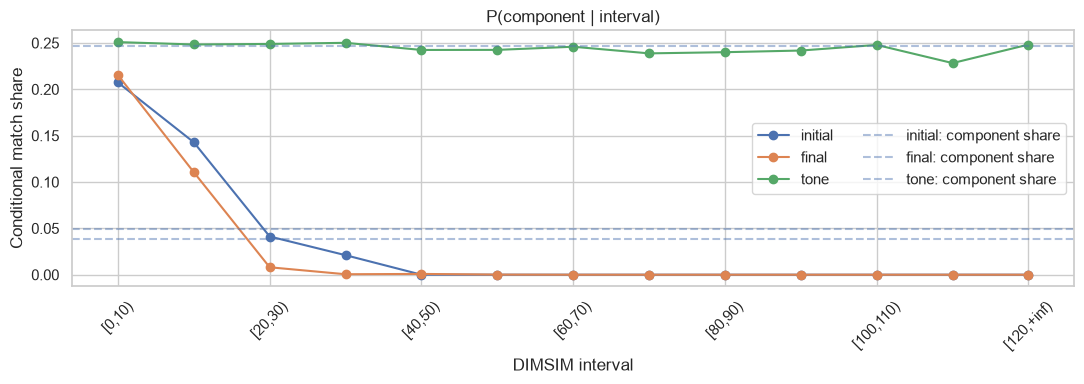

In [6]:
bin_order = [f'[{x},{x+10})' for x in range(0, 120, 10)] + ['[120,+inf)']
bin_cond=pd.DataFrame({label:{'initial':info['equal_initial_share'],'final':info['equal_final_share'],'tone':info['equal_tone_share']} for label,info in summary['bins'].items()}).T.reindex(bin_order)
axis=bin_cond.plot(figsize=(11,4), marker='o')
for component, column in [('initial','equal_initial'),('final','equal_final'),('tone','equal_tone')]: axis.axhline(columns[column].astype(bool).mean(), linestyle='--', alpha=.45, label=f'{component}: component share')
plt.ylabel('Conditional match share'); plt.xlabel('DIMSIM interval'); plt.xticks(rotation=45); plt.title('P(component | interval)'); plt.legend(ncol=2); plt.tight_layout(); plt.show()


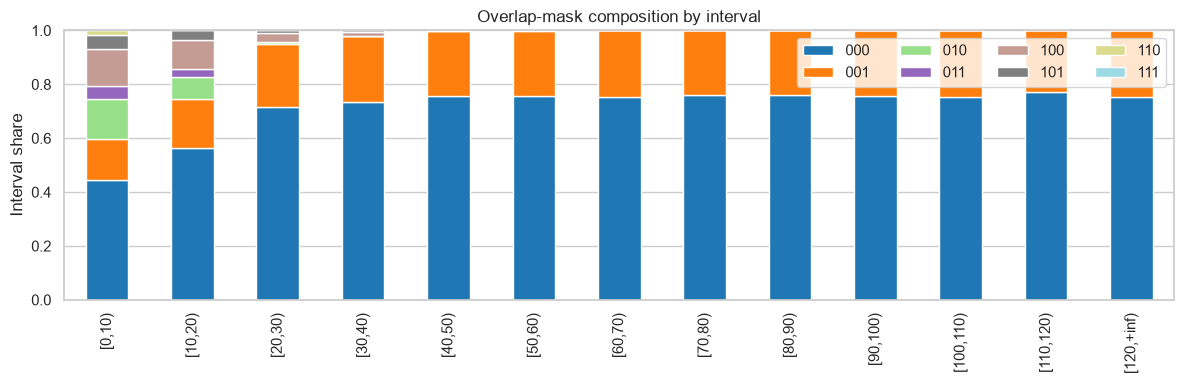

In [7]:
bin_order = [f'[{x},{x+10})' for x in range(0, 120, 10)] + ['[120,+inf)']
mask_order=[f'{x:03b}' for x in range(8)]
mask_bin=pd.DataFrame({label:{m:info['overlap_mask_counts'].get(m,0)/info['count'] if info['count'] else 0 for m in mask_order} for label,info in summary['bins'].items()}).T.reindex(bin_order)
mask_bin.plot(kind='bar', stacked=True, figsize=(12,4), colormap='tab20'); plt.ylabel('Interval share'); plt.title('Overlap-mask composition by interval'); plt.legend(ncol=4); plt.tight_layout(); plt.show()


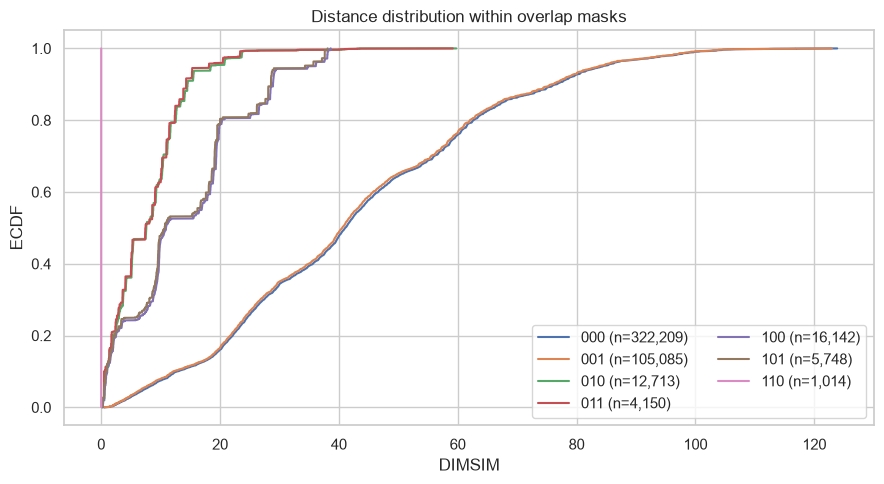

In [8]:
fig, ax=plt.subplots(figsize=(9,5))
for mask in mask_order:
    vals=np.sort(d[columns['overlap_mask']==mask])
    if len(vals): ax.plot(vals,np.arange(1,len(vals)+1)/len(vals),label=f'{mask} (n={len(vals):,})')
ax.set(xlabel='DIMSIM',ylabel='ECDF',title='Distance distribution within overlap masks'); ax.legend(ncol=2); plt.tight_layout(); plt.show()


In [9]:
tone = summary['tone_only']
display(pd.DataFrame([{'tone-only pairs': tone['count'], 'share': tone['share'], **tone['quantiles']}]))


,tone-only pairs,share,q00,q01,q05,q10,q100,q25,q50,q75,q90,q95,q99
0,1014,0.002171,0.000476,0.000476,0.000476,0.000476,0.001905,0.000476,0.000952,0.000952,0.001429,0.001429,0.001429


## Phonetic neighbors inside mask 000

**Question:** do pairs with no identical gold initial, final or tone still contain interpretable phonetic neighbors, and does their prevalence decrease with DIMSIM distance?

We use a fixed, symmetric **expert whitelist**, selected from articulatory contrasts before inspecting its distance trend. It is independent of DIMSIM coordinates and is not fitted to the observed peaks. It is an explanatory heuristic, not an empirically calibrated perceptual-similarity threshold or a complete inventory of possible confusions. Relations are direct edges: `j↔q` and `q↔x` do not imply any additional match by transitivity.

The **core** includes aspiration pairs, corresponding sibilant places of articulation, affricate–fricative relations within a series, selected nasal-coda contrasts, and selected front-vowel rounding contrasts. The **extended** profile adds looser glide/vowel changes and selected consonant contrasts whose similarity may depend on dialect or learner background. Extended results measure sensitivity to the whitelist rather than certify that all these pairs sound equally close. Each explicit relation and its family is listed below.

Normalization uses **gold** components. `v/ü`, `ve/üe`, `van/üan`, `vn/ün` and contracted `ui/uei`, `iu/iou`, `un/uen` are canonicalized. After `j/q/x`, written `u/uan/un` denotes the ü series. Bare `i` after `z/c/s` and `zh/ch/sh/r` is assigned separate apical categories and is never confused with ordinary `i` in `ji/bi`; the two apical categories have an explicit core-neighbor edge. `gu` and `qu` therefore have different normalized finals. `y/w` are absent under the existing nonzero-initial policy.

The phonetic inventory is informed by [Lee & Zee (2003), Standard Chinese (Beijing)](https://doi.org/10.1017/S0025100303001208). **The whitelist and its core/extended boundary are our operational choices**, not a validated similarity list published by those authors. Their description distinguishes vowel realizations and sibilant places; nasal-coda pairs may differ in vowel quality as well as coda.


In [10]:
from phonetics.evaluation.phonetic_matches import classify_pairs, summarize, COMPONENT_INVENTORY
import hashlib

match_core = classify_pairs(columns, profile='core')
match_extended = classify_pairs(columns, profile='extended')
match_summary_core = summarize(columns, profile='core')
match_summary_extended = summarize(columns, profile='extended')
match_bins = pd.DataFrame(match_summary_core['bins'])
match_bins_extended = pd.DataFrame(match_summary_extended['bins'])
assert match_bins['exclusive_sum_ok'].all()
assert match_bins['count'].sum() == len(d)
mask000 = columns['overlap_mask'] == '000'
assert match_bins['mask000_count'].sum() == mask000.sum()
assert np.all(~match_core['close_initial'] | match_extended['close_initial'])
assert np.all(~match_core['close_final'] | match_extended['close_final'])
print(f'Mask 000: {mask000.sum():,} pairs; both tones differ by definition.')
print('Whitelist implementation SHA256:', hashlib.sha256((SOURCE / 'evaluation' / 'phonetic_matches.py').read_bytes()).hexdigest())


Mask 000: 322,209 pairs; both tones differ by definition.
Whitelist implementation SHA256: e1035307f8ba47aa2c36ff1ca22cf4185de3b3abbbe156b564eb7e26c72aa173


In [11]:
match_inventory = pd.DataFrame(COMPONENT_INVENTORY)
match_inventory_compact = match_inventory.groupby(['component', 'profile', 'family'], sort=False)['pair'].agg(', '.join).reset_index()
with pd.option_context('display.max_colwidth', None):
    display(match_inventory_compact)


,component,profile,family,pair
0,initial,core,aspiration,"b–p, c–z, ch–zh, d–t, g–k, j–q"
1,initial,core,sibilant_place,"c–ch, c–q, ch–q, j–z, j–zh, s–sh, s–x, sh–x, z–zh"
2,initial,core,manner,"c–s, ch–sh, j–x, q–x, s–z, sh–zh"
3,initial,extended,dialect_learner_looser,"f–h, h–x, l–n, l–r, r–sh"
4,final,core,nasal_coda,"an–ang, en–eng, in–ing, uan–uang"
5,final,core,frontness_rounding,"i–ü, ian–üan, ie–üe, in–ün"
6,final,core,apical_place,apical_dental–apical_postalveolar
7,final,extended,glide_or_rime_extension,"a–ia, a–ua, ai–uai, an–ian, an–uan, ang–iang, ang–uang, ao–iao, e–ie, e–üe, en–in, en–uen, en–ün, eng–ing, eng–ong, i–ia, i–ie, ian–in, iang–ing, ing–iong, iou–ou, o–uo, u–ua, u–uo, u–ü, uan–üan, uen–ün"


### Composition and denominators

The stacked bars partition **mask 000 within each interval** into four exclusive classes: both components have a listed neighbor, initial only, final only, or neither. All bars use the core whitelist. Bar annotations give the number of mask-000 pairs; an empty bin has no conditional proportion. “Neither” means no listed edge, not proven phonetic dissimilarity.

The line chart reports overlapping events: close initial, close final, either, and both. A dashed line shows the extended-whitelist rate for either component. Each rate has denominator **mask-000 pairs in the same interval**, not all pairs in that interval; the accompanying table provides both denominators. Tone proximity is not evaluated here. Canonically equal finals are retained as a separate classifier flag and are not counted as distinct near-final edges.


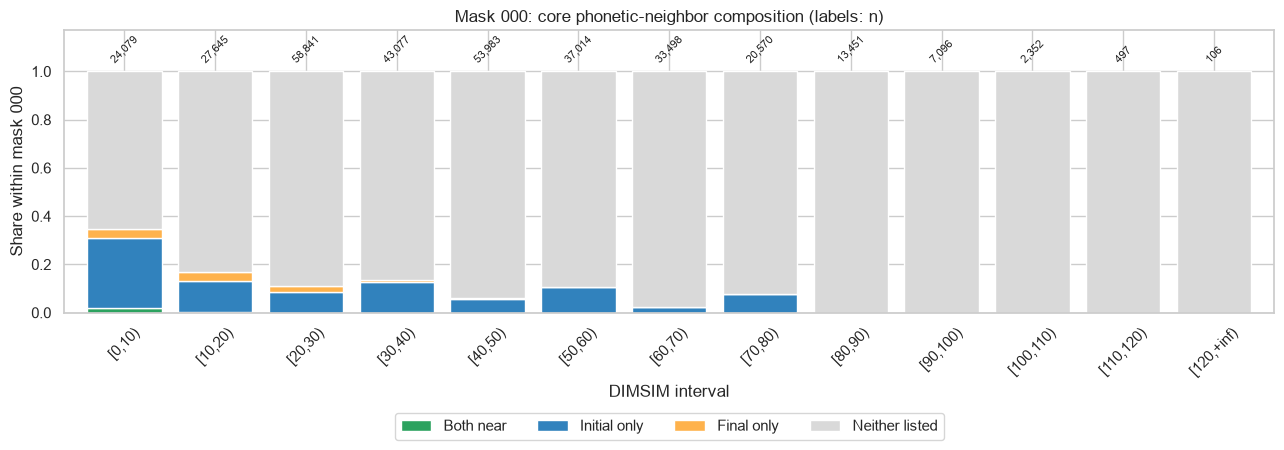

In [12]:
match_classes = [('both', 'Both near'), ('initial_only', 'Initial only'), ('final_only', 'Final only'), ('neither', 'Neither listed')]
match_composition = pd.DataFrame({label: match_bins[key + '_fraction_mask000'].to_numpy() for key, label in match_classes}, index=match_bins['bin'])
fig, ax = plt.subplots(figsize=(13, 5))
match_composition.plot(kind='bar', stacked=True, ax=ax, color=['#2ca25f', '#3182bd', '#feb24c', '#d9d9d9'], width=.82)
for idx, row in match_bins.iterrows():
    ax.text(idx, 1.025, f"{int(row['mask000_count']):,}", ha='center', va='bottom', fontsize=8, rotation=45)
ax.set(xlabel='DIMSIM interval', ylabel='Share within mask 000', ylim=(0, 1.17), title='Mask 000: core phonetic-neighbor composition (labels: n)')
ax.legend(loc='upper center', bbox_to_anchor=(.5, -.33), ncol=4)
ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()


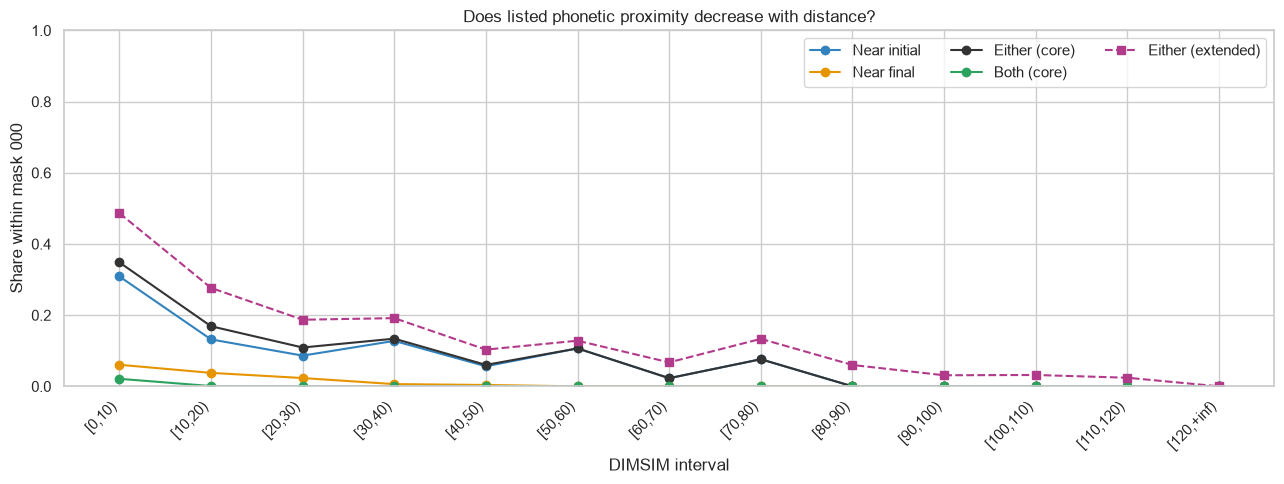

In [13]:
fig, ax = plt.subplots(figsize=(13, 5))
x_match = np.arange(len(match_bins))
for key, label, color in [('close_initial', 'Near initial', '#3182bd'), ('close_final', 'Near final', '#e69500'), ('either', 'Either (core)', '#333333'), ('both', 'Both (core)', '#2ca25f')]:
    ax.plot(x_match, match_bins[key + '_fraction_mask000'], marker='o', label=label, color=color)
ax.plot(x_match, match_bins_extended['either_fraction_mask000'], '--s', color='#b23a8a', label='Either (extended)')
ax.set_xticks(x_match, match_bins['bin'], rotation=45, ha='right')
ax.set(xlabel='DIMSIM interval', ylabel='Share within mask 000', ylim=(0, 1), title='Does listed phonetic proximity decrease with distance?')
ax.legend(ncol=3)
fig.tight_layout()
plt.show()


In [14]:
display(match_bins[['bin', 'count', 'mask000_count', 'close_initial_count', 'close_final_count', 'both_count', 'either_count', 'neither_count', 'either_fraction_mask000', 'either_share_bin']])


,bin,count,mask000_count,close_initial_count,close_final_count,both_count,either_count,neither_count,either_fraction_mask000,either_share_bin
0,"[0,10)",54296,24079,7437,1460,509,8388,15691,0.348353,0.154487
1,"[10,20)",49108,27645,3646,1046,23,4669,22976,0.168891,0.095076
2,"[20,30)",82358,58841,5078,1372,30,6420,52421,0.109108,0.077952
3,"[30,40)",58701,43077,5501,270,0,5771,37306,0.133969,0.098312
4,"[40,50)",71317,53983,3046,207,0,3253,50730,0.060260,0.045613
5,"[50,60)",48869,37014,3944,0,0,3944,33070,0.106554,0.080706
6,"[60,70)",44421,33498,768,0,0,768,32730,0.022927,0.017289
7,"[70,80)",27021,20570,1566,0,0,1566,19004,0.076130,0.057955
8,"[80,90)",17699,13451,0,0,0,0,13451,0.000000,0.000000
9,"[90,100)",9359,7096,0,0,0,0,7096,0.000000,0.000000


In [15]:
# Deterministic trend audit for the complete fixed population: no p-values or iid bootstrap.
trend_rows = []
for profile, table in [('core', match_bins), ('extended', match_bins_extended)]:
    for event in ['close_initial', 'close_final', 'either', 'both']:
        for start, region in [(0, 'all occupied bins'), (4, 'distance >= 40')]:
            rates = table.iloc[start:][event + '_fraction_mask000'].dropna()
            delta = rates.diff().dropna()
            trend_rows.append({'profile': profile, 'event': event, 'region': region,
                'occupied bins': len(rates), 'non-increasing': bool((delta <= 1e-12).all()),
                'upward steps': int((delta > 1e-12).sum()),
                'largest upward step (percentage points)': float(delta.max() * 100) if len(delta) else np.nan,
                'first rate': rates.iloc[0] if len(rates) else np.nan,
                'last rate': rates.iloc[-1] if len(rates) else np.nan})
match_trend = pd.DataFrame(trend_rows)
display(match_trend)


,profile,event,region,occupied bins,non-increasing,upward steps,largest upward step (percentage points),first rate,last rate
0,core,close_initial,all occupied bins,13,False,3,5.320354,0.308858,0.0
1,core,close_initial,distance >= 40,9,False,2,5.320354,0.056425,0.0
2,core,close_final,all occupied bins,13,True,0,0.000000,0.060634,0.0
3,core,close_final,distance >= 40,9,True,0,0.000000,0.003835,0.0
4,core,either,all occupied bins,13,False,3,5.320354,0.348353,0.0
5,core,either,distance >= 40,9,False,2,5.320354,0.060260,0.0
6,core,both,all occupied bins,13,True,0,0.000000,0.021139,0.0
7,core,both,distance >= 40,9,True,0,0.000000,0.000000,0.0
8,extended,close_initial,all occupied bins,13,False,4,5.492636,0.351011,0.0
9,extended,close_initial,distance >= 40,9,False,3,5.492636,0.077376,0.0


In [16]:
# Reproducible examples: nearest to the within-class median in each populated bin >= 40.
example_rows = []
for low in range(40, 121, 10):
    high = low + 10 if low < 120 else np.inf
    in_bin = mask000 & (d >= low) & (d < high)
    for key, label in match_classes:
        chosen = in_bin & (match_core['exclusive_class'] == key)
        ix = np.flatnonzero(chosen)
        if not len(ix):
            continue
        median = np.median(d[ix])
        idx = ix[np.argmin(np.abs(d[ix] - median))]
        example_rows.append({'bin': f'[{low},{low+10})' if low < 120 else '[120,+inf)', 'class': label,
            'class count': len(ix), 'pair': f"{columns['left_pinyin'][idx]}–{columns['right_pinyin'][idx]}",
            'distance': float(d[idx]), 'initial relation': match_core['relation_initial'][idx],
            'final relation': match_core['relation_final'][idx]})
display(pd.DataFrame(example_rows))


,bin,class,class count,pair,distance,initial relation,final relation
0,"[40,50)",Initial only,3046,ci2–sou1,41.330152,manner,
1,"[40,50)",Final only,207,pin3–xun4,47.122884,,frontness_rounding
2,"[40,50)",Neither listed,50730,shi1–ku3,44.332843,,
3,"[50,60)",Initial only,3944,bi3–pa4,57.532397,aspiration,
4,"[50,60)",Neither listed,33070,ping2–hai4,55.965220,,
5,"[60,70)",Initial only,768,jiang3–xin4,60.983289,manner,
6,"[60,70)",Neither listed,32730,kou4–xin1,63.584499,,
7,"[70,80)",Initial only,1566,su1–shang4,76.106486,sibilant_place,
8,"[70,80)",Neither listed,19004,fu3–huan1,75.811850,,
9,"[80,90)",Neither listed,13451,cang1–lu3,83.955058,,


### The same phonetic-neighbor diagnostic for mask 001

Mask `001` means that the **tone is identical**, while the gold initial and final are both different. The graph below repeats the preceding conditional-rate analysis for this population. Its denominator is the number of mask-001 pairs in each DIMSIM interval. The same fixed core and extended whitelists are used; the whitelist is not refitted for mask `001`.


In [17]:
def phonetic_match_bins(mask_value, classified):
    rows = []
    target_mask = columns['overlap_mask'] == mask_value
    for low in range(0, 121, 10):
        high = low + 10 if low < 120 else np.inf
        label = f'[{low},{low+10})' if low < 120 else '[120,+inf)'
        selected = target_mask & (d >= low) & (d < high)
        denominator = int(selected.sum())
        close_initial = classified['close_initial'] & selected
        close_final = classified['close_final'] & selected
        both = close_initial & close_final
        values = {
            'close_initial': int(close_initial.sum()),
            'close_final': int(close_final.sum()),
            'either': int((close_initial | close_final).sum()),
            'both': int(both.sum()),
        }
        row = {'bin': label, 'count': denominator}
        for name, count in values.items():
            row[name + '_count'] = count
            row[name + '_fraction'] = count / denominator if denominator else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

match001_core = phonetic_match_bins('001', match_core)
match001_extended = phonetic_match_bins('001', match_extended)
assert match001_core['count'].sum() == int((columns['overlap_mask'] == '001').sum())
display(match001_core[['bin', 'count', 'close_initial_count', 'close_final_count', 'both_count', 'either_count']])


,bin,count,close_initial_count,close_final_count,both_count,either_count
0,"[0,10)",8279,2595,500,178,2917
1,"[10,20)",9020,1367,324,9,1682
2,"[20,30)",19463,1643,478,8,2113
3,"[30,40)",14358,1971,91,0,2062
4,"[40,50)",17274,941,58,0,999
5,"[50,60)",11849,1385,0,0,1385
6,"[60,70)",10923,182,0,0,182
7,"[70,80)",6451,509,0,0,509
8,"[80,90)",4248,0,0,0,0
9,"[90,100)",2263,0,0,0,0


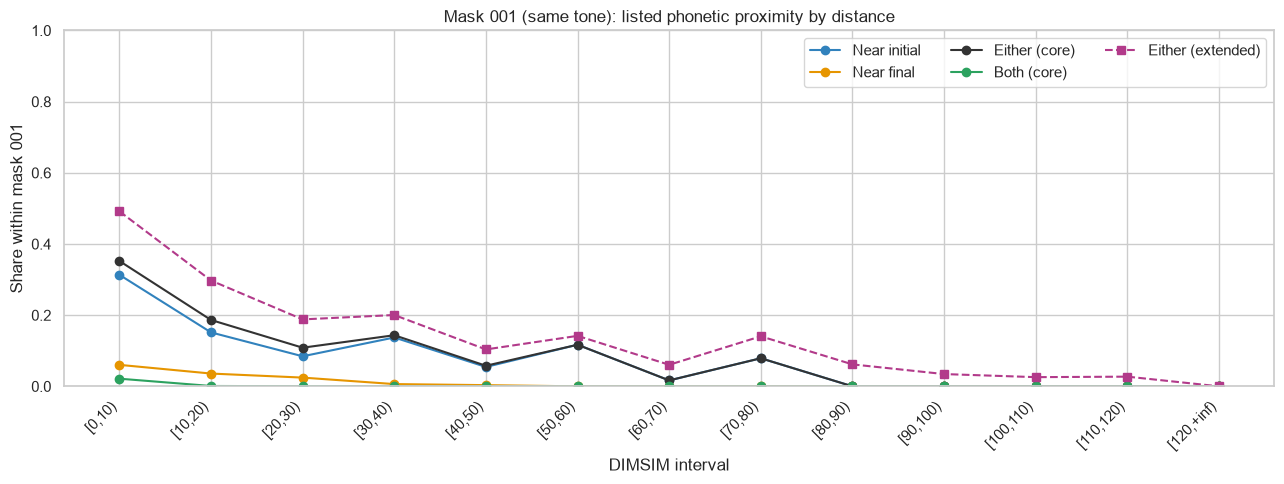

In [18]:
fig, ax = plt.subplots(figsize=(13, 5))
x_match001 = np.arange(len(match001_core))
for key, label, color in [('close_initial', 'Near initial', '#3182bd'), ('close_final', 'Near final', '#e69500'), ('either', 'Either (core)', '#333333'), ('both', 'Both (core)', '#2ca25f')]:
    ax.plot(x_match001, match001_core[key + '_fraction'], marker='o', label=label, color=color)
ax.plot(x_match001, match001_extended['either_fraction'], '--s', color='#b23a8a', label='Either (extended)')
ax.set_xticks(x_match001, match001_core['bin'], rotation=45, ha='right')
ax.set(xlabel='DIMSIM interval', ylabel='Share within mask 001', ylim=(0, 1), title='Mask 001 (same tone): listed phonetic proximity by distance')
ax.legend(ncol=3)
fig.tight_layout()
plt.show()


### Observed result for the fixed population

Mask `000` contains **322,209** pairs. The prevalence of at least one core-neighbor component declines broadly but **does not decline monotonically**: it is **34.8%** in `[0,10)`, **6.0%** in `[40,50)`, **10.7%** in `[50,60)`, **2.3%** in `[60,70)`, and **7.6%** in `[70,80)`. There are three upward steps across all bins, including two from 40 onward; the largest is **5.32 percentage points**. Core matches disappear from 80 onward for this population and this list.

The core **final-neighbor** rate is non-increasing across all 13 bins and is zero from 50 onward. The core **initial-neighbor** rate has local rebounds and drives the non-monotonic combined rate. Core matches for **both** components are absent from 30 onward. With the extended whitelist, neither the final-neighbor rate nor the combined rate is monotonic, so the conclusion depends on how phonetic proximity is operationalized.

Examples above 40 include **pin3–xun4 (47.12)**, whose normalized finals `in↔ün` form a rounding relation; **bi3–pa4 (57.53)**, with aspiration-related `b↔p`; **jiang3–xin4 (60.98)**, with `j↔x`; and **su1–shang4 (76.11)**, with `s↔sh`. Their other components differ. These are interpretable component correspondences at large DIMSIM values, not evidence that the whole syllable pairs are perceptually close. Local rebounds show that a higher bin does not uniformly remove every kind of component proximity.


### How to read the trend

The trend table tests exact non-increase across occupied 10-unit bins, both overall and from 40 onward, and reports upward steps in percentage points. A broad downward tendency can coexist with local reversals. Sparse tail bins must be read with their absolute counts. Changing bin width or the whitelist can change the pattern; no threshold is selected by optimizing this curve.

Even a near initial is only one part of a syllable: its final and tone can differ substantially. A decline in this heuristic rate supports an association with the selected contrasts; it does not validate all DIMSIM rankings, equal distance increments, or a universal perceptual scale. Conversely, a local increase can reflect the mixture of available syllables and components rather than an implementation error. The diagnostic addresses the full fixed syllable population and retains its unequal tone-variant multiplicities.


## Mean DIMSIM component shares by interval

This decomposition uses **all pairs**, without conditioning on overlap masks. For each pair, the initial, final and tone terms are multiplied by the same DIMSIM difference multiplier. Their means are calculated within each interval and divided by the sum of those three means. Thus each stacked bar shows the share of the **mean DIMSIM distance** attributable to each component in that interval.

No `hardcodeMap` override is active in this population, so the three contributions sum to the public DIMSIM distance for every pair. The chart describes the internal formula's scale; it does not turn the components into calibrated acoustic or perceptual quantities.


In [19]:
initial_contribution = columns['consonant_distance'].astype(float) * columns['multiplier'].astype(float)
final_contribution = columns['vowel_distance'].astype(float) * columns['multiplier'].astype(float)
tone_contribution = columns['tone_distance'].astype(float) * columns['multiplier'].astype(float)
component_total = initial_contribution + final_contribution + tone_contribution
assert not columns['hardcode_applied'].astype(bool).any()
assert np.allclose(component_total, d, rtol=1e-12, atol=1e-12)

component_rows = []
for low in range(0, 121, 10):
    high = low + 10 if low < 120 else np.inf
    label = f'[{low},{low+10})' if low < 120 else '[120,+inf)'
    selected = (d >= low) & (d < high)
    means = {
        'Initial': float(initial_contribution[selected].mean()),
        'Final': float(final_contribution[selected].mean()),
        'Tone': float(tone_contribution[selected].mean()),
    }
    mean_distance = float(d[selected].mean())
    component_rows.append({
        'bin': label,
        'count': int(selected.sum()),
        'mean distance': mean_distance,
        **{f'mean {name.lower()} contribution': value for name, value in means.items()},
        **{f'{name} share': value / mean_distance for name, value in means.items()},
    })
component_shares = pd.DataFrame(component_rows)
assert np.allclose(component_shares[['Initial share', 'Final share', 'Tone share']].sum(axis=1), 1.0)
display(component_shares)


,bin,count,mean distance,mean initial contribution,mean final contribution,mean tone contribution,Initial share,Final share,Tone share
0,"[0,10)",54296,5.249904,2.779178,2.371916,0.098809,0.529377,0.451802,0.018821
1,"[10,20)",49108,15.396351,8.040682,7.245996,0.109673,0.522246,0.470631,0.007123
2,"[20,30)",82358,24.867205,12.164173,12.579875,0.123157,0.489165,0.505882,0.004953
3,"[30,40)",58701,35.887960,14.714573,21.048359,0.125028,0.410014,0.586502,0.003484
4,"[40,50)",71317,44.322408,15.460269,28.733325,0.128814,0.348814,0.648280,0.002906
5,"[50,60)",48869,55.823799,16.653142,39.042542,0.128115,0.298316,0.699389,0.002295
6,"[60,70)",44421,63.952873,19.991224,43.835562,0.126087,0.312593,0.685435,0.001972
7,"[70,80)",27021,75.522747,18.628183,56.768203,0.126362,0.246657,0.751670,0.001673
8,"[80,90)",17699,83.962632,22.794744,61.040938,0.126950,0.271487,0.727001,0.001512
9,"[90,100)",9359,95.211643,24.461611,70.626694,0.123337,0.256918,0.741786,0.001295


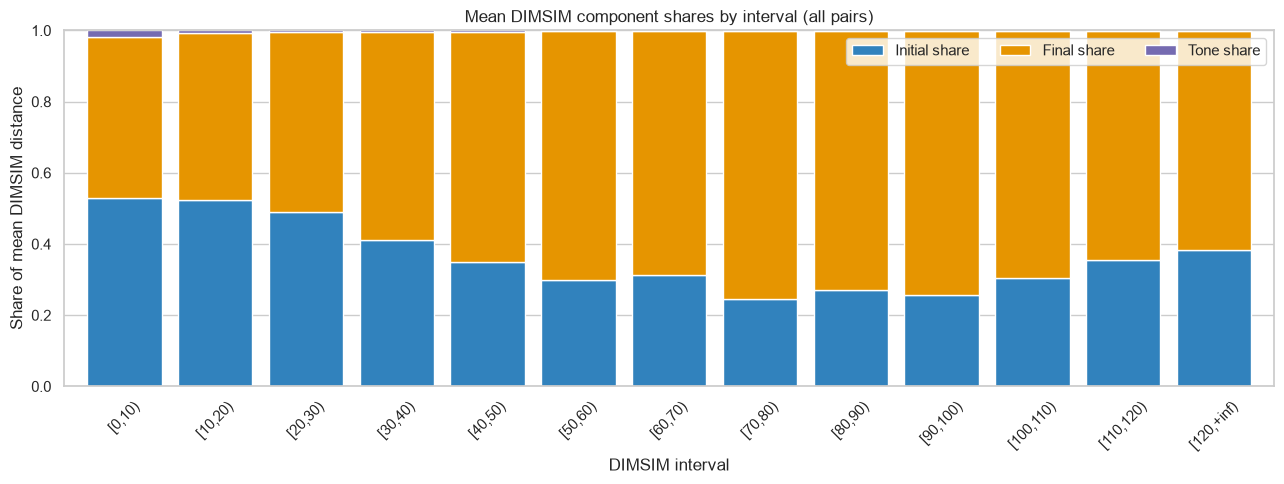

In [20]:
fig, ax = plt.subplots(figsize=(13, 5))
component_shares.set_index('bin')[['Initial share', 'Final share', 'Tone share']].plot(
    kind='bar', stacked=True, ax=ax, width=.82, color=['#3182bd', '#e69500', '#756bb1'])
ax.set(xlabel='DIMSIM interval', ylabel='Share of mean DIMSIM distance', ylim=(0, 1), title='Mean DIMSIM component shares by interval (all pairs)')
ax.tick_params(axis='x', rotation=45)
ax.legend(ncol=3)
fig.tight_layout()
plt.show()


## Mode robustness and reweighting

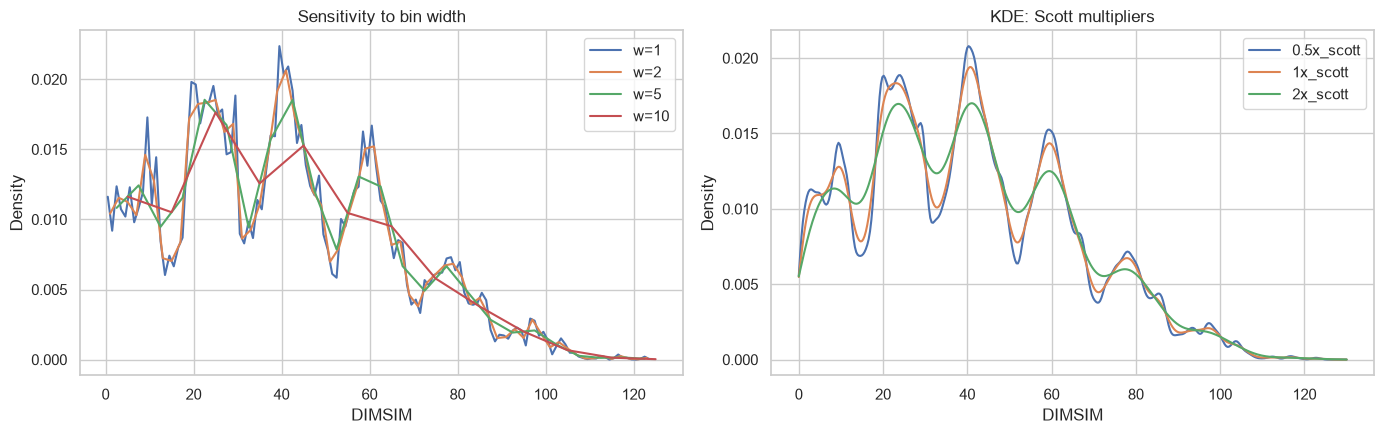

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for width in (1,2,5,10):
    counts, edges = np.histogram(d, bins=np.arange(0, np.ceil(d.max()/width)*width+width, width))
    axes[0].plot((edges[:-1]+edges[1:])/2, counts/counts.sum()/width, label=f'w={width}')
axes[0].set(title='Sensitivity to bin width', xlabel='DIMSIM', ylabel='Density'); axes[0].legend()
kde = summary['kde']; grid=np.asarray(kde['grid'])
for name, curve in kde['curves'].items(): axes[1].plot(grid, curve['density'], label=name)
axes[1].set(title='KDE: Scott multipliers', xlabel='DIMSIM', ylabel='Density'); axes[1].legend()
plt.tight_layout(); plt.show()


In [22]:
display(pd.DataFrame(summary['modal_composition_width_1']))


,count,final_pairs,initial_pairs,left,mask_counts,right
0,10445,"[{'count': 271, 'enrichment': 3.15329111374438...","[{'count': 338, 'enrichment': 5.31811576944209...",39.0,"{'000': 7716, '001': 2729}",40.0
1,9767,"[{'count': 163, 'enrichment': 3.54305048540074...","[{'count': 250, 'enrichment': 4.10545272148758...",41.0,"{'000': 7303, '001': 2448, '010': 13, '011': 3}",42.0
2,9252,"[{'count': 209, 'enrichment': 4.78493092870524...","[{'count': 266, 'enrichment': 5.89475687481566...",19.0,"{'000': 4880, '001': 1605, '010': 18, '011': 7...",20.0
3,9119,"[{'count': 209, 'enrichment': 3.97204267385208...","[{'count': 303, 'enrichment': 5.04197168177232...",24.0,"{'000': 6855, '001': 2190, '010': 16, '101': 58}",25.0
4,8799,"[{'count': 433, 'enrichment': 5.98077960920795...","[{'count': 465, 'enrichment': 6.25829936533909...",29.0,"{'000': 6368, '001': 1963, '100': 440, '101': 28}",30.0
5,8335,"[{'count': 209, 'enrichment': 3.04750131940824...","[{'count': 318, 'enrichment': 6.23931507816083...",26.0,"{'000': 5994, '001': 1731, '010': 12, '011': 4...",27.0
6,8071,"[{'count': 180, 'enrichment': 5.33355182433323...","[{'count': 385, 'enrichment': 9.78032456461633...",9.0,"{'000': 2930, '001': 867, '010': 837, '011': 2...",10.0
7,7819,"[{'count': 138, 'enrichment': 4.28223744026787...","[{'count': 264, 'enrichment': 5.95986577262955...",44.0,"{'000': 6026, '001': 1793}",45.0


In [23]:
mode_rows=[]
for center in (23.5,40.5,59.5):
    selected=(d>=center-2)&(d<center+2)
    mode_rows.append({'window':f'{center-2:.1f}–{center+2:.1f}','n':int(selected.sum()),
      'mean consonant distance':columns['consonant_distance'][selected].astype(float).mean(),
      'mean vowel distance':columns['vowel_distance'][selected].astype(float).mean(),
      'mean tone term':columns['tone_distance'][selected].astype(float).mean(),
      'mean multiplier':columns['multiplier'][selected].astype(float).mean()})
display(pd.DataFrame(mode_rows))


,window,n,mean consonant distance,mean vowel distance,mean tone term,mean multiplier
0,21.5–25.5,34415,12.637274,12.217290,0.132878,0.948784
1,38.5–42.5,38577,12.844925,29.521698,0.133269,0.954881
2,57.5–61.5,28838,17.496342,44.588162,0.131531,0.955997


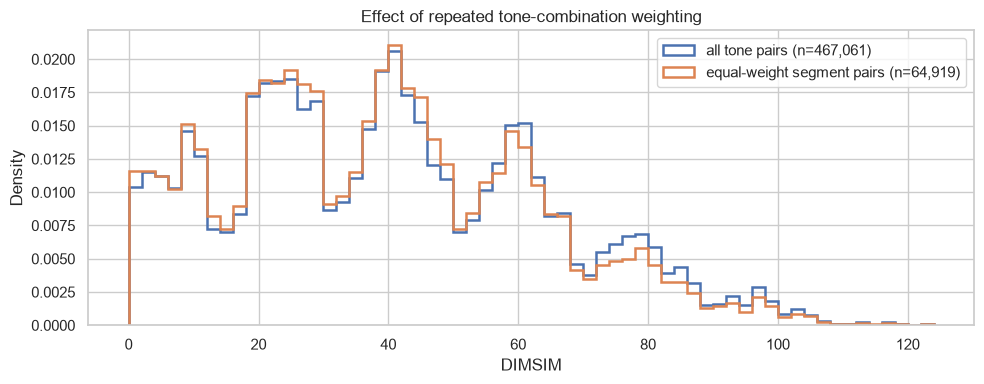

In [24]:
segments=pd.DataFrame({'left':[x[:-1] for x in columns['left_pinyin']], 'right':[x[:-1] for x in columns['right_pinyin']], 'distance':d})
segments['pair']=segments.apply(lambda r:'|'.join(sorted((r['left'],r['right']))),axis=1)
segment_means=segments.groupby('pair',sort=True)['distance'].mean().to_numpy()
fig,ax=plt.subplots(figsize=(10,4)); bins=np.arange(0,126,2)
ax.hist(d,bins=bins,density=True,histtype='step',linewidth=1.8,label=f'all tone pairs (n={len(d):,})')
ax.hist(segment_means,bins=bins,density=True,histtype='step',linewidth=1.8,label=f'equal-weight segment pairs (n={len(segment_means):,})')
ax.set(xlabel='DIMSIM',ylabel='Density',title='Effect of repeated tone-combination weighting'); ax.legend(); plt.tight_layout(); plt.show()


In [25]:
display(pd.DataFrame([summary['segment_pair_reweighted']]))


,mean,median,quantiles,unique_segment_pair_count
0,38.614673,37.761787,"{'q00': 0.0004761904761904762, 'q01': 0.554604...",64919


## Interval composition: prevalence and enrichment

In [26]:
bin_order = [f'[{x},{x+10})' for x in range(0, 120, 10)] + ['[120,+inf)']
interpretation = {'[0,10)': 'Component matches and nearby coordinates are common. The tone-only scale is visible separately near 10^-3.', '[10,20)': 'Moderate shifts within or between neighboring map regions prevail; phonetic proximity is plausible, but DIMSIM coordinates determine the value.', '[20,30)': 'Mixed composition; different initials and finals are common. No single articulatory series accounts for this interval.', '[30,40)': 'Several segment combinations contribute to this transition region and its multimodality.', '[40,50)': 'A broad central region whose pairs do not support one phonetic interpretation.', '[50,60)': 'Pairs with different initials and finals become more common; several component combinations contribute.', '[60,70)': 'Large segmental shifts occur across several series, without one phonological class explaining the interval.', '[70,80)': 'Combinations involving m and the internal u/v final codes reveal the influence of distant coordinates.', '[80,90)': 'Combinations involving b/p/m and u versus front or nasal finals reflect the geometry of the code map.', '[90,100)': 'Specific coordinate gaps involving m and u increasingly shape the tail.', '[100,110)': 'Prominent b/p↔m and a/an/ang↔u combinations do not justify interpreting the magnitude as a calibrated phonetic distance.', '[110,120)': 'Combinations involving f/k/h↔m and a/ian/iao↔u reflect extreme coordinate gaps.', '[120,+inf)': 'The 141 pairs form a narrow extreme-coordinate tail, including m↔b/p and a/an/ian↔u combinations.'}
rows=[]
for label in bin_order:
    info = summary['bins'][label]
    i=info['initial_pair_enrichment']; f=info['final_pair_enrichment']
    examples=(i['enriched_examples'][0]['examples'] if i['enriched_examples'] else [])
    rows.append({'interval':label,'n':info['count'],
      'prevalent initials':', '.join(f"{x['pair']} ({x['count']})" for x in i['prevalent'][:2]),
      'enriched initials':', '.join(f"{x['pair']} ({x['count']}; ×{x['enrichment']:.1f})" for x in i['enriched_min_count_5'][:2]),
      'prevalent finals':', '.join(f"{x['pair']} ({x['count']})" for x in f['prevalent'][:2]),
      'example':'; '.join(f"{x['left']}–{x['right']}: {x['distance']:.2f}" for x in examples[:2]),
      'cautious interpretation':interpretation[label]})
pd.DataFrame(rows)


,interval,n,prevalent initials,enriched initials,prevalent finals,example,cautious interpretation
0,"[0,10)",54296,"l|l (1139), d|t (920)","g|g (670; ×4.9), t|t (888; ×4.6)","i|i (1417), u|u (1098)",gai4–guang3: 3.02; guai3–gua4: 3.02,Component matches and nearby coordinates are c...
1,"[10,20)",49108,"l|t (918), d|l (878)","f|f (196; ×4.6), r|r (117; ×4.0)","an|ao (778), ang|ao (715)",fei1–fu2: 19.38; fei2–fu1: 19.38,Moderate shifts within or between neighboring ...
2,"[20,30)",82358,"ch|l (1031), l|zh (1025)","j|r (310; ×1.7), j|j (261; ×1.7)","i|u (1707), an|ao (906)",jiu1–ran3: 26.03; ran2–jiu4: 26.03,Mixed composition; different initials and fina...
3,"[30,40)",58701,"h|l (998), g|l (926)","t|z (686; ×2.4), d|z (670; ×2.4)","i|u (804), ao|ou (717)",ti1–zu1: 36.21; ti2–zu2: 36.21,Several segment combinations contribute to thi...
4,"[40,50)",71317,"ch|l (967), l|m (916)","b|f (444; ×2.1), r|sh (396; ×2.1)","i|ong (917), i|uo (892)",bei4–fu4: 44.90; bu4–fei4: 44.90,A broad central region whose pairs do not supp...
5,"[50,60)",48869,"ch|d (812), h|l (798)","f|r (242; ×3.3), f|n (340; ×2.7)","ai|i (975), ao|i (926)",feng2–ruan3: 53.29; feng4–ruan3: 53.29,Pairs with different initials and finals becom...
6,"[60,70)",44421,"l|m (760), b|ch (739)","f|sh (498; ×3.5), f|s (325; ×3.2)","an|i (896), ou|u (856)",fan1–she2: 63.28; fan2–she3: 63.28,Large segmental shifts occur across several se...
7,"[70,80)",27021,"d|m (637), m|t (622)","h|m (611; ×3.9), d|m (637; ×3.9)","an|i (1108), ao|u (1018)",hua1–mei3: 77.92; hua2–mei4: 77.92,Combinations involving m and the internal u/v ...
8,"[80,90)",17699,"m|p (551), b|m (542)","b|m (542; ×6.1), b|j (445; ×5.9)","an|u (920), ao|u (843)",bei4–mian4: 84.96; bian3–mei3: 84.96,Combinations involving b/p/m and u versus fron...
9,"[90,100)",9359,"g|m (270), d|m (269)","g|m (270; ×5.5), k|m (185; ×4.7)","an|u (1032), ao|u (905)",ming2–gua1: 96.94; ming2–gua3: 96.94,Specific coordinate gaps involving m and u inc...


## Gold labels and the DIMSIM internal parser

In [27]:
print('Pairs with raw representation differences:', summary['parser_mismatches']['count'])
print('j/q/x + u among affected endpoints:', summary['parser_mismatches']['j_q_x_plus_u_endpoint_syllables'])
display(pd.DataFrame(summary['parser_mismatches']['examples']))


Pairs with raw representation differences: 42480
j/q/x + u among affected endpoints: ['ju1', 'ju2', 'ju3', 'ju4', 'juan1', 'juan3', 'juan4', 'jue2', 'jun1', 'jun4', 'qu1', 'qu2', 'qu3', 'qu4', 'quan1', 'quan2', 'quan3', 'quan4', 'que1', 'que4', 'qun2', 'xu1', 'xu2', 'xu3', 'xu4', 'xuan1', 'xuan2', 'xuan3', 'xuan4', 'xue1', 'xue2', 'xue3', 'xue4', 'xun1', 'xun2', 'xun4']


,distance,left,overlap_mask,right
0,40.820878,hong1,000,juan3
1,40.820878,hong2,000,juan4
2,40.820878,hong3,000,juan1
3,40.819613,xue2,000,cu1
4,40.819613,xue3,000,cu4


In [28]:
diff=[]
for side in ('left','right'):
    for values in zip(columns[f'{side}_pinyin'],columns[f'{side}_gold_initial'],columns[f'{side}_gold_final'],columns[f'{side}_gold_tone'],columns[f'{side}_library_initial'],columns[f'{side}_library_final'],columns[f'{side}_library_tone']):
        py,gi,gf,gt,li,lf,lt=values
        if (gi,gf,int(gt)) != (li,lf,int(lt)): diff.append({'pinyin':py,'gold_initial':gi,'gold_final':gf,'gold_tone':gt,'library_initial':li,'library_final':lf,'library_tone':lt})
display(pd.DataFrame(diff).drop_duplicates().sort_values('pinyin').head(60))


,pinyin,gold_initial,gold_final,gold_tone,library_initial,library_final,library_tone
3736,gu1,g,u,1,g,u:,1
11885,gu3,g,u,3,g,u:,3
10415,gu4,g,u,4,g,u:,4
7177,ju1,j,v,1,j,u:,1
24704,ju2,j,v,2,j,u:,2
20090,ju3,j,v,3,j,u:,3
2828,ju4,j,v,4,j,u:,4
21105,juan1,j,van,1,j,uan,1
23855,juan3,j,van,3,j,uan,3
21561,juan4,j,van,4,j,uan,4


In [29]:
print('hardcodeMap activations under literal identity comparisons:', summary['validation']['hardcode_applied_pair_count'])


hardcodeMap activations under literal identity comparisons: 0


## Tails and leave-one-out sensitivity

In [30]:
tail_rows=[]
for key, info in summary['tails'].items():
    tail_rows.append({'region':key,'count':info['count'],'share':info['share'],'unique_syllables':info['unique_syllables']})
display(pd.DataFrame(tail_rows))


,region,count,share,unique_syllables
0,ge_100,3912,0.008376,464
1,ge_120,141,0.000302,47
2,ge_60,102412,0.219269,967
3,ge_90,13271,0.028414,582
4,lt_60,364649,0.780731,967


In [31]:
display(pd.DataFrame(summary['tails']['ge_120']['leave_one_out']))


,endpoint_count,remaining_pair_count,removed_share,syllable
0,25,116,0.177305,mu3
1,25,116,0.177305,mu4
2,13,128,0.092199,pu3
3,13,128,0.092199,bu4
4,13,128,0.092199,pu4
5,13,128,0.092199,pu2
6,13,128,0.092199,bu3
7,13,128,0.092199,bu2
8,13,128,0.092199,pu1
9,7,134,0.049645,ma3


## Cluster diagnostics

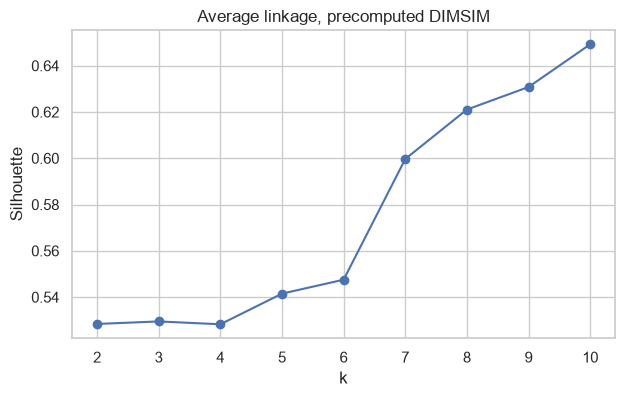

In [32]:
scores = {int(k): v['silhouette'] for k, v in summary['clustering'].items()}
k_order = sorted(scores)
plt.figure(figsize=(7,4))
plt.plot(k_order, [scores[k] for k in k_order], marker='o')
plt.xticks(k_order)
plt.xlabel('k'); plt.ylabel('Silhouette')
plt.title('Average linkage, precomputed DIMSIM')
plt.show()


In [33]:
display(pd.DataFrame([{'k':int(k),'silhouette':v['silhouette'], 'sizes':[c['count'] for c in v['clusters']]} for k,v in summary['clustering'].items()]).sort_values('k').reset_index(drop=True))


,k,silhouette,sizes
0,2,0.528394,"[395, 572]"
1,3,0.529480,"[395, 48, 524]"
2,4,0.528254,"[62, 333, 48, 524]"
3,5,0.541486,"[62, 117, 216, 48, 524]"
4,6,0.547515,"[62, 117, 216, 48, 135, 389]"
5,7,0.599680,"[62, 117, 216, 48, 135, 170, 219]"
6,8,0.621043,"[62, 117, 92, 124, 48, 135, 170, 219]"
7,9,0.630789,"[62, 117, 92, 124, 29, 19, 135, 170, 219]"
8,10,0.649247,"[62, 81, 36, 92, 124, 29, 19, 135, 170, 219]"


In [34]:
display(pd.DataFrame(summary['clustering']['10']['clusters']))


,cluster,count,finals,initials,tones
0,1,62,"[[u, 58], [v, 4]]","[[ch, 4], [d, 4], [f, 4], [h, 4], [l, 4]]","[[4, 17], [3, 16], [2, 15], [1, 14]]"
1,2,81,"[[i, 43], [ing, 15], [v, 12], [in, 11]]","[[j, 14], [x, 14], [q, 12], [l, 11], [n, 6]]","[[4, 23], [3, 21], [2, 18], [1, 17], [5, 2]]"
2,3,36,"[[i, 16], [ing, 11], [in, 6], [u, 3]]","[[p, 10], [b, 9], [d, 7], [t, 7], [g, 3]]","[[1, 11], [3, 9], [4, 9], [2, 7]]"
3,4,92,"[[eng, 20], [ui, 15], [en, 14], [e, 13], [ei, ...","[[h, 16], [g, 13], [f, 12], [d, 11], [k, 11]]","[[1, 31], [4, 24], [2, 19], [3, 17], [5, 1]]"
4,5,124,"[[e, 21], [eng, 19], [en, 17], [ui, 16], [ie, ...","[[sh, 16], [ch, 15], [zh, 14], [l, 13], [x, 11]]","[[4, 39], [1, 30], [2, 28], [3, 24], [5, 3]]"
5,6,29,"[[a, 5], [o, 4], [ai, 3], [an, 3], [ao, 3]]","[[m, 29]]","[[2, 9], [3, 8], [4, 8], [1, 3], [5, 1]]"
6,7,19,"[[i, 4], [ei, 3], [en, 3], [eng, 3], [in, 2]]","[[m, 19]]","[[2, 6], [4, 6], [3, 4], [5, 2], [1, 1]]"
7,8,135,"[[ou, 38], [uo, 36], [ong, 35], [iu, 15], [o, 7]]","[[l, 12], [t, 12], [d, 11], [g, 10], [h, 10]]","[[4, 37], [1, 36], [3, 32], [2, 29], [5, 1]]"
8,9,170,"[[an, 27], [ao, 23], [a, 22], [ang, 21], [ai, ...","[[t, 26], [d, 24], [h, 24], [b, 23], [g, 23]]","[[1, 52], [4, 48], [3, 41], [2, 28], [5, 1]]"
9,10,219,"[[ao, 29], [an, 25], [ang, 23], [a, 22], [ai, ...","[[l, 28], [ch, 24], [sh, 22], [zh, 22], [x, 19]]","[[4, 61], [3, 58], [1, 57], [2, 42], [5, 1]]"


## Historical populations

In [35]:
rows=[]; mask_rows=[]
for level, info in historical['levels'].items():
    rows.append({'level':level,'count':info['count'],**info['quantiles'],**info['tail_counts']})
    total=sum(info['overlap_mask_counts'].values())
    mask_rows.extend({'level':level,'mask':m,'count':n,'share':n/total} for m,n in info['overlap_mask_counts'].items())
rows.append({'level':'syllable_full','count':summary['distribution']['count'],**summary['distribution']['quantiles'],**{k:v['count'] for k,v in summary['tails'].items() if k.startswith('ge_')}})
display(pd.DataFrame(rows)); display(pd.DataFrame(mask_rows))


,level,count,q00,q01,q05,q10,q100,q25,q50,q75,q90,q95,q99,ge_100,ge_120,ge_60,ge_90
0,character_pinyin,12000,0.000000,0.485621,3.158571,8.425154,122.895305,22.047300,40.633664,60.709918,77.841839,84.622373,100.010643,121,4,3195,402
1,contextual,12000,0.000000,0.000952,3.047619,8.630694,123.660943,21.459372,39.251236,57.727385,73.897911,80.683489,97.731594,73,4,2558,249
2,syllable_full,467061,0.000476,0.769524,4.514465,9.060142,123.852372,21.522642,38.923528,57.917710,74.971633,83.114257,99.116691,3912,141,102412,13271


,level,mask,count,share
0,character_pinyin,000,7880,0.656667
1,character_pinyin,001,2840,0.236667
2,character_pinyin,010,430,0.035833
3,character_pinyin,011,155,0.012917
4,character_pinyin,100,412,0.034333
5,character_pinyin,101,211,0.017583
6,character_pinyin,110,41,0.003417
7,character_pinyin,111,31,0.002583
8,contextual,000,8133,0.677750
9,contextual,001,2484,0.207000


## Interpretation and limitations

- Initial-consonant relationships can be described by place and manner of articulation, aspiration, sibilant, retroflex and palatal series. Final relationships can involve rounding and nasal endings. DIMSIM nevertheless uses fixed two-dimensional coordinates and a multiplier based on the number of differing components; its scale is not a calibrated acoustic scale.
- The formula was reconstructed from pinned `dimsim==0.2.2` and checked against the public API on every pair. The component distances and tone term are combined with the library's difference-fraction multiplier. Successful reconstruction verifies implementation consistency, not perceptual validity.
- Gold bundle components and DIMSIM internal components are kept separately. Orthographic normalization and parser differences, including `j/q/x + u`, require interpretation before calling them labeling errors.
- Historical contextual and character–pinyin samples are used descriptively. Embeddings were not recomputed; hypotheses about model geometry must be distinguished from properties of DIMSIM itself.
- KDE peaks depend on smoothing, so robustness across bandwidths matters. Average-linkage clustering is diagnostic: peaks in a pair-distance distribution do not establish clusters of syllables. The highest silhouette at the boundary of the tested k range does not establish a natural number of clusters.
